# Fast L² bandwidth distributions: sample size and lambda

Start with the Figure 3.6 baseline: **ten separate bandwidth distributions** for $n=100,200,\ldots,1000$, at **$\lambda=1$**. Each panel shows **only spectrally chosen bandwidths**. There are no ISE or Q-hat distributions and no reference lines.

Use the existing FFT-based Gaussian KDE implementation with

$$D_{ij}=\frac12\|\widehat f_{h_i}-\widehat f_{h_j}\|_2^2,\qquad S_{ij}=\exp(-\lambda D_{ij}).$$

Select the bandwidth at the largest Perron-vector component. Keep the original L² experiment's geometric grid, sampling seed, and nested samples. The default thesis profile uses $M=1000$ repetitions and $N=201$ candidates on $[0.01,2]$, with the periodic FFT interval $[-12,12)$ and 8,192 spatial points.

**Run the cells in order.** `LAMBDA_VALUES = [1.0]` gives the requested baseline first. To compare larger lambda values later, extend this list, for example to `[1.0, 10.0, 100.0, 1000.0]`, and rerun from the settings cell. Each lambda receives its own ten-panel figure. All lambdas share the same samples, and the FFT divergence matrix is calculated once per sample and reused across lambdas. Checkpoints and exports are kept separately for each complete configuration.

Sources: [Figure 3.6 / increasing-sample-size experiment, `fig:distribution_of_chosen_bandwidths_for_increasing_sample_size`](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex); [original fast L² experiment, section 3 / `beta2_n_sweep_*`](spectral_scale_selection_kde.ipynb); [shared FFT divergence helper](kde_tools/fourier/similarities.py); [shared periodic KDE reconstruction](kde_tools/fourier/reconstruction.py).


In [2]:
from __future__ import annotations

import csv
import hashlib
import json
import os
import sys
import time
from pathlib import Path

working_directory = Path.cwd().resolve()
code_directory = next(
    (candidate.resolve()
     for root in (working_directory, *working_directory.parents)
     for candidate in (root, root / "Code" / "Code_kde")
     if (candidate / "kde_tools" / "pdf_export.py").is_file()),
    None,
)
if code_directory is None:
    raise FileNotFoundError("Run this notebook from the project or Code/Code_kde folder.")
if str(code_directory) not in sys.path:
    sys.path.insert(0, str(code_directory))
os.environ.setdefault("MPLCONFIGDIR", str(code_directory / ".matplotlib-cache"))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import PercentFormatter
from scipy.linalg import eigh as symmetric_eigh

from kde_tools.bandwidths import bandwidth_grid_linear_in_psi_beta
from kde_tools.fourier import beta2_divergence_matrix_fft
from kde_tools.pdf_export import enable_automatic_pdf_saving
from kde_tools.similarities import beta2_divergence_matrix

notebook_name = "fast_l2_bandwidth_distributions_vs_n_lambda"
pdf_output_directory = enable_automatic_pdf_saving(
    notebook_name, output_root=code_directory / "outputs" / "pdfs"
)
data_output_directory = code_directory / "outputs" / "data" / notebook_name
image_output_directory = code_directory / "outputs" / "images" / notebook_name
print(f"Automatic PDF exports: {pdf_output_directory}")


Automatic PDF exports: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda


## Settings: lambda = 1 baseline

The default values match the fast L² sample-size experiment: $n=100,200,\ldots,1000$, $M=1000$, $N=201$, $h_{\min}=0.01$, $h_{\max}=2$, and seed `20260830` (the original notebook's `seed + 10 + 2`). One maximum-size Gaussian sample is drawn per repetition and its prefixes are used at every $n$.

The preview profile reduces the repetition count to 100 while keeping the same bandwidth and FFT grids. `LAMBDA_VALUES` controls subsequent comparisons; leave `[1.0]` for the first experiment.

Source: [the original fast L² notebook's setup, beta-2 settings, and increasing-sample-size cell](spectral_scale_selection_kde.ipynb).


In [4]:
RUN_PROFILE = "thesis"  # "thesis" or "preview"
PROFILES = {
    "thesis": {"repetitions": 1000, "grid_size": 201},
    "preview": {"repetitions": 100, "grid_size": 201},
}
SAMPLE_SIZES = list(range(100, 1001, 100))
LAMBDA_VALUES = [1.0]  # Start here; later extend to [1.0, 10.0, 100.0, 1000.0].
REUSE_CHECKPOINTS = True
VALIDATE_FFT = True

settings = {
    **PROFILES[RUN_PROFILE],
    "sigma2": 1.0,
    "h_min": 0.01,
    "h_max": 2.0,
    "fft_half_width": 12.0,
    "fft_spatial_points": 8192,
    "seed": 20260830,
    "maximum_sample_size": max(SAMPLE_SIZES),
}
LAMBDA_VALUES = [float(value) for value in LAMBDA_VALUES]
if (not LAMBDA_VALUES or LAMBDA_VALUES[0] != 1.0
        or not np.all(np.isfinite(LAMBDA_VALUES))
        or np.any(np.diff(LAMBDA_VALUES) <= 0)):
    raise ValueError("Start LAMBDA_VALUES with 1.0 and use finite, strictly increasing values.")
if settings["repetitions"] < 1 or settings["grid_size"] < 2:
    raise ValueError("Repetitions must be positive and the bandwidth grid needs two points.")
if settings["sigma2"] <= 0 or settings["fft_half_width"] <= 0:
    raise ValueError("Variance and FFT half-width must be positive.")
if settings["fft_spatial_points"] < 2 or settings["fft_spatial_points"] % 2:
    raise ValueError("The FFT grid needs an even number of at least two points.")
h_grid = bandwidth_grid_linear_in_psi_beta(
    h_min=settings["h_min"], h_max=settings["h_max"], beta=2.0,
    grid_size=settings["grid_size"],
)
configuration = {
    "settings": settings, "sample_sizes": SAMPLE_SIZES,
    "lambda_values": LAMBDA_VALUES, "method": "fft_l2_spectral",
    "implementation_version": 1,
}
configuration_id = hashlib.sha256(json.dumps(configuration, sort_keys=True).encode()).hexdigest()[:12]
run_directory = data_output_directory / RUN_PROFILE / configuration_id
image_directory = image_output_directory / RUN_PROFILE / configuration_id
for directory in (run_directory, image_directory):
    directory.mkdir(parents=True, exist_ok=True)
(run_directory / "settings.json").write_text(
    json.dumps({"profile": RUN_PROFILE, **configuration}, indent=2) + "\n"
)
full_samples = np.random.default_rng(settings["seed"]).normal(
    0.0, np.sqrt(settings["sigma2"]),
    size=(settings["repetitions"], settings["maximum_sample_size"]),
)
print(f"Sample sizes: {SAMPLE_SIZES}; lambdas: {LAMBDA_VALUES}")
print(f"Profile: {RUN_PROFILE}; M={settings['repetitions']}; N={len(h_grid)}; "
      f"FFT spatial points={settings['fft_spatial_points']}")
print(f"Checkpoints and CSV data: {run_directory}")


Sample sizes: [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]; lambdas: [1.0]
Profile: thesis; M=1000; N=201; FFT spatial points=8192
Checkpoints and CSV data: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/028fa8664f9c


## Fast L² calculation and spectral selection

Use the shared FFT divergence function directly. For each sample, reuse the resulting $D$ matrix for every configured lambda.

The eigenvector calculation follows the stable construction already used in `experiment_1_joint_N_lambda_limit.ipynb`: subtract the identity and rescale the off-diagonal similarity matrix before computing its largest eigenvector. This preserves the selected Perron peak and supports later runs with larger lambda values. Only the largest eigenvector is computed.

The original fast L² sample-size experiment selects the peak of the Doob stationary mass. For a symmetric similarity matrix, the shared implementation uses equal left and right Perron vectors, so that mass is proportional to the square of the Perron vector. **Consequently, both choices have the same maximizer** (this is the direct algebraic consequence of the shared implementation).

Sources: [stable eigenvector helpers in the joint-limit notebook](experiment_1_joint_N_lambda_limit.ipynb); [thesis subsection “Convergence to closest adjacent pair,” identity subtraction and positive rescaling](../../Abschlussarbeit_2021/LaTeX/chapters/5_bandwidth_selection.tex); [`doob_stationary_mass` and Perron-vector implementations](kde_tools/similarities.py); [FFT divergence implementation](kde_tools/fourier/similarities.py).


In [5]:
def fast_spectral_index(divergence, lambda_value):
    """Select the Perron peak using the existing stable off-diagonal construction."""
    divergence = np.asarray(divergence, dtype=float)
    if divergence.ndim != 2 or divergence.shape[0] != divergence.shape[1] or len(divergence) < 2:
        raise ValueError("Divergence must be a square matrix with at least two scales.")
    if (not np.all(np.isfinite(divergence)) or np.any(divergence < 0)
            or not np.allclose(divergence, divergence.T, atol=1e-12)):
        raise ValueError("Divergence must be finite, symmetric, and nonnegative.")
    lambda_value = float(lambda_value)
    if not np.isfinite(lambda_value) or lambda_value <= 0:
        raise ValueError("Lambda must be positive and finite.")
    # Same construction as stable_perron_vector_from_divergence in the joint-limit notebook.
    matrix = lambda_value * divergence
    np.fill_diagonal(matrix, np.inf)
    minimum_exponent = float(np.min(matrix))
    matrix -= minimum_exponent
    np.negative(matrix, out=matrix)
    np.exp(matrix, out=matrix)
    np.fill_diagonal(matrix, 0.0)
    number_of_scales = len(matrix)
    _, eigenvectors = symmetric_eigh(
        matrix, subset_by_index=[number_of_scales - 1, number_of_scales - 1],
        check_finite=False, overwrite_a=True, driver="evr",
    )
    vector = eigenvectors[:, 0]
    if vector.sum() < 0:
        vector = -vector
    return int(np.argmax(vector))


def validate_l2_checkpoint(indices, completed, repetitions, number_of_lambdas, grid_size):
    if indices.shape != (repetitions, number_of_lambdas):
        raise ValueError("Checkpoint shape differs from the current experiment.")
    if not np.issubdtype(indices.dtype, np.integer):
        raise ValueError("Checkpoint selections must be integer indices.")
    if not 0 <= completed <= repetitions:
        raise ValueError("Invalid checkpoint completion count.")
    if np.any(indices[:completed] < 0) or np.any(indices[:completed] >= grid_size):
        raise ValueError("Checkpoint contains invalid selected indices.")


def run_l2_point(sample_size, full_samples, h_grid, settings, lambda_values, output_directory, *, reuse=True):
    """One FFT divergence calculation per repetition, reused for all lambdas."""
    repetitions = int(settings["repetitions"])
    if full_samples.shape != (repetitions, settings["maximum_sample_size"]):
        raise ValueError("Sample array shape differs from the settings.")
    if not 1 <= sample_size <= full_samples.shape[1]:
        raise ValueError("Sample size is outside the generated sample range.")
    point_json = json.dumps({
        "settings": settings, "sample_size": int(sample_size),
        "lambda_values": list(lambda_values), "implementation_version": 1,
    }, sort_keys=True)
    point_directory = Path(output_directory) / f"n{int(sample_size)}"
    point_directory.mkdir(parents=True, exist_ok=True)
    checkpoint_path = point_directory / "checkpoint.npz"
    indices = np.full((repetitions, len(lambda_values)), -1, dtype=int)
    completed = 0

    def save_checkpoint():
        temporary = checkpoint_path.with_suffix(".npz.tmp")
        with temporary.open("wb") as stream:
            np.savez_compressed(
                stream, configuration_json=point_json, h_grid=h_grid,
                selected_indices=indices, completed=completed,
            )
        temporary.replace(checkpoint_path)

    if reuse and checkpoint_path.exists():
        with np.load(checkpoint_path, allow_pickle=False) as checkpoint:
            if str(checkpoint["configuration_json"].item()) != point_json:
                raise ValueError("L² checkpoint settings differ from the current configuration.")
            if not np.array_equal(checkpoint["h_grid"], h_grid):
                raise ValueError("L² checkpoint bandwidth grid differs from the current grid.")
            indices = checkpoint["selected_indices"].copy()
            completed = int(checkpoint["completed"].item())
    validate_l2_checkpoint(indices, completed, repetitions, len(lambda_values), len(h_grid))
    started = time.perf_counter()
    print(f"n={sample_size}: starting at {completed}/{repetitions}", flush=True)
    for repetition in range(completed, repetitions):
        divergence = beta2_divergence_matrix_fft(
            samples=full_samples[repetition, :int(sample_size)], h_grid=h_grid,
            half_width=settings["fft_half_width"], spatial_points=settings["fft_spatial_points"],
        )
        for column, lambda_value in enumerate(lambda_values):
            indices[repetition, column] = fast_spectral_index(divergence, lambda_value)
        completed = repetition + 1
        save_checkpoint()
        if completed == 1 or completed % 100 == 0 or completed == repetitions:
            print(f"n={sample_size}: {completed}/{repetitions}; elapsed this run: "
                  f"{time.perf_counter() - started:.1f}s", flush=True)
    validate_l2_checkpoint(indices, completed, repetitions, len(lambda_values), len(h_grid))
    counts = np.stack([
        np.bincount(indices[:, column], minlength=len(h_grid))
        for column in range(len(lambda_values))
    ])
    frequencies = counts / repetitions
    assert np.all(counts.sum(axis=1) == repetitions)
    assert np.allclose(frequencies.sum(axis=1), 1.0)
    return {"sample_size": int(sample_size), "selected_indices": indices,
            "counts": counts, "frequencies": frequencies}


## Small FFT validation

Compare the FFT divergence with the shared exact Gaussian formula on a small subset of bandwidths from the first sample. This check precedes the repeated simulation and does not compute any additional bandwidth-selection distribution.

Sources: [FFT validation in the original L² notebook](spectral_scale_selection_kde.ipynb); [exact Gaussian L² helper](kde_tools/similarities.py).


In [6]:
if VALIDATE_FFT:
    validation_indices = np.unique(np.linspace(0, len(h_grid) - 1, min(len(h_grid), 20), dtype=int))
    validation_h_grid = h_grid[validation_indices]
    validation_samples = full_samples[0, :min(100, settings["maximum_sample_size"])]
    validation_exact = beta2_divergence_matrix(validation_samples, validation_h_grid)
    validation_fft = beta2_divergence_matrix_fft(
        validation_samples, validation_h_grid,
        half_width=settings["fft_half_width"], spatial_points=settings["fft_spatial_points"],
    )
    validation_absolute_error = float(np.max(np.abs(validation_fft - validation_exact)))
    validation_relative_error = validation_absolute_error / max(float(np.max(validation_exact)), np.finfo(float).tiny)
    print(f"FFT validation: maximum absolute D2 error={validation_absolute_error:.3e}; "
          f"error relative to max(D2)={validation_relative_error:.3e}")
    if validation_relative_error > 2e-5:
        raise ArithmeticError("FFT validation failed; increase the FFT resolution or interval before running.")


FFT validation: maximum absolute D2 error=1.626e-14; error relative to max(D2)=1.040e-13


## Repeated spectral selections

The next cell computes the ten sample-size distributions for every configured lambda, sharing samples across both sample sizes and lambda values. A checkpoint is saved after every completed repetition. Rerunning with unchanged settings resumes that run.


In [22]:
results_by_n = {}
for current_n in SAMPLE_SIZES:
    results_by_n[current_n] = run_l2_point(
        current_n, full_samples, h_grid, settings, LAMBDA_VALUES, run_directory,
        reuse=REUSE_CHECKPOINTS,
    )
print(f"Completed {len(SAMPLE_SIZES)} distributions per lambda for {LAMBDA_VALUES}.")


n=100: starting at 1000/1000
n=200: starting at 984/1000
n=200: 1000/1000; elapsed this run: 9.1s
n=300: starting at 0/1000
n=300: 1/1000; elapsed this run: 1.2s
n=300: 100/1000; elapsed this run: 58.8s
n=300: 200/1000; elapsed this run: 126.0s
n=300: 300/1000; elapsed this run: 181.3s
n=300: 400/1000; elapsed this run: 234.5s
n=300: 500/1000; elapsed this run: 288.0s
n=300: 600/1000; elapsed this run: 342.4s
n=300: 700/1000; elapsed this run: 394.6s
n=300: 800/1000; elapsed this run: 447.9s
n=300: 900/1000; elapsed this run: 502.7s
n=300: 1000/1000; elapsed this run: 557.6s
n=400: starting at 0/1000
n=400: 1/1000; elapsed this run: 0.6s
n=400: 100/1000; elapsed this run: 56.5s
n=400: 200/1000; elapsed this run: 112.2s
n=400: 300/1000; elapsed this run: 171.2s
n=400: 400/1000; elapsed this run: 228.3s
n=400: 500/1000; elapsed this run: 288.0s
n=400: 600/1000; elapsed this run: 343.1s
n=400: 700/1000; elapsed this run: 400.1s
n=400: 800/1000; elapsed this run: 471.7s
n=400: 900/1000; el

## Saved spectral selections and distributions

Export the chosen bandwidth for each repetition, the grid frequencies, and one summary row for each sample size and lambda. These files contain spectral selections only.


In [23]:
selection_rows = []
frequency_rows = []
summary_rows = []
for current_n in SAMPLE_SIZES:
    result = results_by_n[current_n]
    for column, lambda_value in enumerate(LAMBDA_VALUES):
        chosen_indices = result["selected_indices"][:, column]
        chosen_h = h_grid[chosen_indices]
        selection_rows.extend(
            {"n": current_n, "lambda": lambda_value, "repetition": repetition,
             "grid_index": int(index), "h": float(h_grid[index])}
            for repetition, index in enumerate(chosen_indices)
        )
        frequency_rows.extend(
            {"n": current_n, "lambda": lambda_value, "grid_index": index,
             "h": float(h), "count": int(result["counts"][column, index]),
             "relative_frequency": float(result["frequencies"][column, index])}
            for index, h in enumerate(h_grid)
        )
        modal_index = int(np.argmax(result["counts"][column]))
        summary_rows.append({
            "n": current_n, "lambda": lambda_value, "repetitions": settings["repetitions"],
            "modal_h": float(h_grid[modal_index]), "mean_h": float(np.mean(chosen_h)),
            "median_h": float(np.median(chosen_h)),
            "modal_frequency": float(result["frequencies"][column, modal_index]),
        })
for filename, rows in (
    ("selections.csv", selection_rows), ("frequencies.csv", frequency_rows),
    ("summary.csv", summary_rows),
):
    with (run_directory / filename).open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)
print(f"CSV data: {run_directory}")
print(f"{'lambda':>9s} {'n':>5s} {'modal h':>10s} {'mean h':>10s} {'median h':>10s}")
for row in sorted(summary_rows, key=lambda row: (row["lambda"], row["n"])):
    print(f"{row['lambda']:9g} {row['n']:5d} {row['modal_h']:10.5f} "
          f"{row['mean_h']:10.5f} {row['median_h']:10.5f}")


CSV data: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/028fa8664f9c
   lambda     n    modal h     mean h   median h
        1   100    0.08549    0.09899    0.09256
        1   200    0.09014    0.10311    0.09256
        1   300    0.08779    0.12656    0.09760
        1   400    0.41901    0.19315    0.11441
        1   500    0.44181    0.26734    0.29693
        1   600    0.44181    0.33403    0.41901
        1   700    0.44181    0.38439    0.43026
        1   800    0.44181    0.41381    0.44181
        1   900    0.44181    0.43127    0.44181
        1  1000    0.45367    0.43817    0.44181


## First figure: ten spectral L² distributions at lambda = 1

The first displayed figure always contains the ten distributions at $\lambda=1$, arranged in a 5 × 2 grid. Each panel contains one spectral histogram. Subsequent lambda values, when configured, receive the same layout in increasing order. Horizontal and vertical limits are shared across all displayed figures.

Every displayed figure is automatically saved as a PDF under `outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda/`; a PNG copy is also saved. No ISE distribution, Q-hat distribution, or reference line is added.

Source for the experiment and geometric-grid plotting convention: [original Figure 3.6 workflow](spectral_scale_selection_kde.ipynb).


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda/005_fast_l_2_spectral_bandwidth_distributions_lambda_1_gaussian_data_m_1000_per_n_n_.pdf


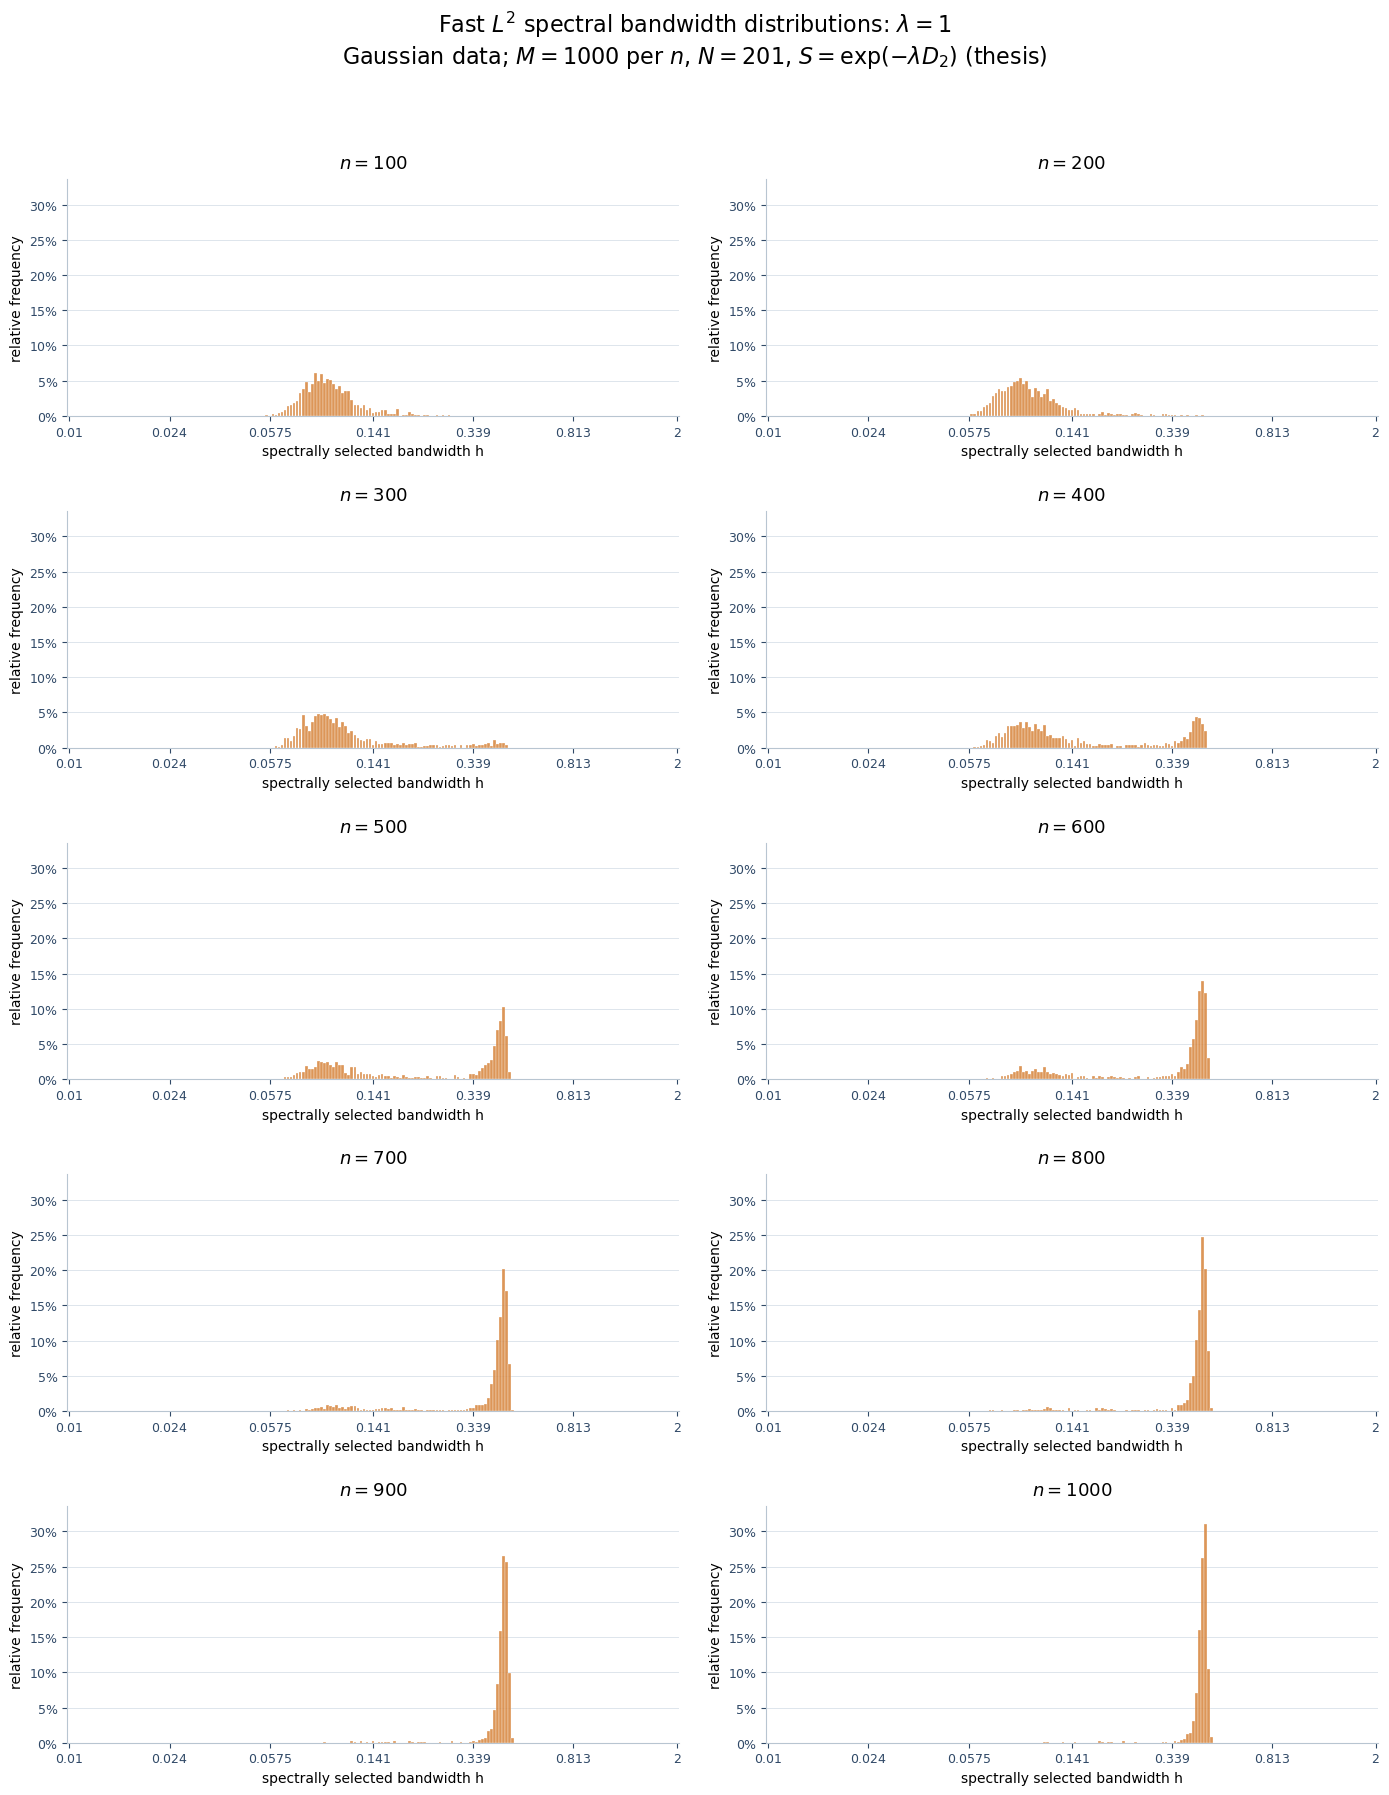

PNG (lambda=1): /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/028fa8664f9c/spectral_l2_lambda1_M1000_N201.png
PDF directory: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda


In [24]:
if set(results_by_n) != set(SAMPLE_SIZES):
    raise RuntimeError("Finish all ten sample sizes before plotting.")
grid_positions = np.arange(len(h_grid))
ticks = np.unique(np.linspace(0, len(h_grid) - 1, 7, dtype=int))
y_max = 1.08 * max(np.max(result["frequencies"]) for result in results_by_n.values())

for column, lambda_value in enumerate(LAMBDA_VALUES):
    fig, axes = plt.subplots(5, 2, figsize=(14, 18), sharex=True, sharey=True)
    for ax, current_n in zip(axes.flat, SAMPLE_SIZES):
        ax.bar(
            grid_positions, results_by_n[current_n]["frequencies"][column],
            width=0.86, color="#D6843B", alpha=0.85, edgecolor="white", linewidth=0.25,
        )
        ax.set_title(rf"$n={current_n}$", fontsize=13, pad=8)
        ax.set_xticks(ticks, [f"{h_grid[index]:.3g}" for index in ticks])
        ax.set_xlim(-0.7, len(h_grid) - 0.3)
        ax.set_ylim(0, y_max)
        ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
        ax.set_xlabel("spectrally selected bandwidth h", fontsize=10)
        ax.set_ylabel("relative frequency", fontsize=10)
        ax.tick_params(labelsize=9, colors="#304967", labelbottom=True, labelleft=True)
        ax.grid(axis="y", color="#DDE5EC", linewidth=0.7)
        ax.set_axisbelow(True)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#B8C5D1")
    fig.suptitle(
        rf"Fast $L^2$ spectral bandwidth distributions: $\lambda={lambda_value:g}$" + "\n"
        + rf"Gaussian data; $M={settings['repetitions']}$ per $n$, $N={len(h_grid)}$, "
        + r"$S=\exp(-\lambda D_2)$" + f" ({RUN_PROFILE})",
        fontsize=16, y=0.995,
    )
    fig.tight_layout(rect=(0, 0, 1, 0.965), h_pad=2.0, w_pad=2.0)
    lambda_tag = f"{lambda_value:g}".replace(".", "p").replace("+", "")
    png_path = image_directory / (
        f"spectral_l2_lambda{lambda_tag}_M{settings['repetitions']}_N{len(h_grid)}.png"
    )
    fig.savefig(png_path, dpi=160, bbox_inches="tight")
    plt.show()  # The shared automatic exporter saves each ten-panel figure as a PDF.
    plt.close(fig)
    print(f"PNG (lambda={lambda_value:g}): {png_path}")
print(f"PDF directory: {pdf_output_directory}")


## Additional experiments: lambda = 10, 100, and 1000

Run the cells below after the setup, settings, FFT validation, and function-definition cells above. This section adds **ten spectral-only distributions for each of** $\lambda=10,100,1000$, using the same Gaussian samples, bandwidth grid, FFT settings, and repetition count as the $\lambda=1$ baseline. The active preview profile uses $M=100$; the thesis profile uses $M=1000$.

The baseline settings, results, and exported files are retained. Each sample's FFT divergence matrix is computed once and reused for the three additional lambda values. The new configuration has its own resumable checkpoints and CSV/PNG output folders. Each displayed figure is automatically saved as a PDF by the exporter enabled in setup.

The three new figures each contain ten separate panels for $n=100,200,\ldots,1000$, with common horizontal and vertical limits. Only spectrally selected bandwidths are plotted.

Sources: the `run_l2_point` and `fast_spectral_index` functions above; [shared FFT divergence helper](kde_tools/fourier/similarities.py); [automatic PDF exporter](kde_tools/pdf_export.py).


In [11]:
# ADDITIONAL_LAMBDA_VALUES = [10.0, 100.0, 1000.0]
ADDITIONAL_LAMBDA_VALUES = [1000.0]

required_names = (
    "settings", "full_samples", "h_grid", "SAMPLE_SIZES", "run_l2_point",
    "data_output_directory", "image_output_directory", "pdf_output_directory", "RUN_PROFILE",
)
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError("Run the setup, settings, and function cells above first. Missing: "
                       + ", ".join(missing_names))
additional_settings = dict(settings)
additional_configuration = {
    "settings": additional_settings, "sample_sizes": list(SAMPLE_SIZES),
    "lambda_values": ADDITIONAL_LAMBDA_VALUES, "method": "fft_l2_spectral",
    "implementation_version": 1,
}
additional_configuration_id = hashlib.sha256(
    json.dumps(additional_configuration, sort_keys=True).encode()
).hexdigest()[:12]
additional_run_directory = data_output_directory / RUN_PROFILE / additional_configuration_id
additional_image_directory = image_output_directory / RUN_PROFILE / additional_configuration_id
for additional_directory in (additional_run_directory, additional_image_directory):
    additional_directory.mkdir(parents=True, exist_ok=True)
(additional_run_directory / "settings.json").write_text(
    json.dumps({"profile": RUN_PROFILE, **additional_configuration}, indent=2) + "\n"
)
print(f"Additional lambdas: {ADDITIONAL_LAMBDA_VALUES}; sample sizes: {SAMPLE_SIZES}")
print(f"Using the baseline samples and grid: M={additional_settings['repetitions']}, N={len(h_grid)}")
print(f"Additional checkpoints and CSV data: {additional_run_directory}")


Additional lambdas: [1000.0]; sample sizes: [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000]
Using the baseline samples and grid: M=1000, N=201
Additional checkpoints and CSV data: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/d7062cba5620


In [12]:
additional_results_by_n = {}
for additional_n in SAMPLE_SIZES:
    additional_results_by_n[additional_n] = run_l2_point(
        additional_n, full_samples, h_grid, additional_settings,
        ADDITIONAL_LAMBDA_VALUES, additional_run_directory,
        reuse=REUSE_CHECKPOINTS,
    )
print(f"Completed {len(SAMPLE_SIZES)} distributions per lambda for {ADDITIONAL_LAMBDA_VALUES}.")


n=100: starting at 0/1000
n=100: 1/1000; elapsed this run: 0.4s
n=100: 100/1000; elapsed this run: 50.4s
n=100: 200/1000; elapsed this run: 100.1s
n=100: 300/1000; elapsed this run: 150.3s
n=100: 400/1000; elapsed this run: 199.3s
n=100: 500/1000; elapsed this run: 249.0s
n=100: 600/1000; elapsed this run: 299.0s
n=100: 700/1000; elapsed this run: 348.0s
n=100: 800/1000; elapsed this run: 396.6s
n=100: 900/1000; elapsed this run: 446.3s
n=100: 1000/1000; elapsed this run: 495.3s
n=200: starting at 0/1000
n=200: 1/1000; elapsed this run: 0.5s
n=200: 100/1000; elapsed this run: 51.7s
n=200: 200/1000; elapsed this run: 102.6s
n=200: 300/1000; elapsed this run: 153.2s
n=200: 400/1000; elapsed this run: 205.0s
n=200: 500/1000; elapsed this run: 255.7s
n=200: 600/1000; elapsed this run: 305.7s
n=200: 700/1000; elapsed this run: 357.1s
n=200: 800/1000; elapsed this run: 411.0s
n=200: 900/1000; elapsed this run: 466.2s
n=200: 1000/1000; elapsed this run: 518.7s
n=300: starting at 0/1000
n=300:

### Additional spectral selection data

Save selections, grid frequencies, and summaries for the three additional lambda values in their own output folder.


In [13]:
additional_selection_rows = []
additional_frequency_rows = []
additional_summary_rows = []
for additional_n in SAMPLE_SIZES:
    additional_result = additional_results_by_n[additional_n]
    for additional_column, additional_lambda_value in enumerate(ADDITIONAL_LAMBDA_VALUES):
        additional_chosen_indices = additional_result["selected_indices"][:, additional_column]
        additional_chosen_h = h_grid[additional_chosen_indices]
        additional_selection_rows.extend(
            {"n": additional_n, "lambda": additional_lambda_value, "repetition": repetition,
             "grid_index": int(index), "h": float(h_grid[index])}
            for repetition, index in enumerate(additional_chosen_indices)
        )
        additional_frequency_rows.extend(
            {"n": additional_n, "lambda": additional_lambda_value, "grid_index": index,
             "h": float(h), "count": int(additional_result["counts"][additional_column, index]),
             "relative_frequency": float(additional_result["frequencies"][additional_column, index])}
            for index, h in enumerate(h_grid)
        )
        additional_modal_index = int(np.argmax(additional_result["counts"][additional_column]))
        additional_summary_rows.append({
            "n": additional_n, "lambda": additional_lambda_value, "repetitions": additional_settings["repetitions"],
            "modal_h": float(h_grid[additional_modal_index]), "mean_h": float(np.mean(additional_chosen_h)),
            "median_h": float(np.median(additional_chosen_h)),
            "modal_frequency": float(additional_result["frequencies"][additional_column, additional_modal_index]),
        })
for additional_filename, additional_rows in (
    ("selections.csv", additional_selection_rows), ("frequencies.csv", additional_frequency_rows),
    ("summary.csv", additional_summary_rows),
):
    with (additional_run_directory / additional_filename).open("w", newline="") as additional_stream:
        additional_writer = csv.DictWriter(additional_stream, fieldnames=additional_rows[0].keys())
        additional_writer.writeheader()
        additional_writer.writerows(additional_rows)
print(f"CSV data: {additional_run_directory}")
print(f"{'lambda':>9s} {'n':>5s} {'modal h':>10s} {'mean h':>10s} {'median h':>10s}")
for additional_row in sorted(additional_summary_rows, key=lambda additional_row: (additional_row["lambda"], additional_row["n"])):
    print(f"{additional_row['lambda']:9g} {additional_row['n']:5d} {additional_row['modal_h']:10.5f} "
          f"{additional_row['mean_h']:10.5f} {additional_row['median_h']:10.5f}")


CSV data: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/d7062cba5620
   lambda     n    modal h     mean h   median h
     1000   100    0.31309    0.29607    0.29693
     1000   200    0.25330    0.24278    0.24022
     1000   300    0.21607    0.21469    0.21607
     1000   400    0.20492    0.19630    0.19435
     1000   500    0.18432    0.18294    0.18432
     1000   600    0.16145    0.17204    0.17024
     1000   700    0.16145    0.16325    0.16145
     1000   800    0.15312    0.15563    0.15312
     1000   900    0.14912    0.14996    0.14912
     1000  1000    0.14522    0.14469    0.14522


### Ten distributions each for lambda = 10, 100, and 1000

Run this cell after the additional sampling cell finishes. It displays three figures, in the order $\lambda=10,100,1000$, each with ten separate spectral histograms. The three figures share axis limits and are exported automatically as PDFs and as PNG copies.


Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda/002_fast_l_2_spectral_bandwidth_distributions_lambda_1000_gaussian_data_m_1000_per_n.pdf


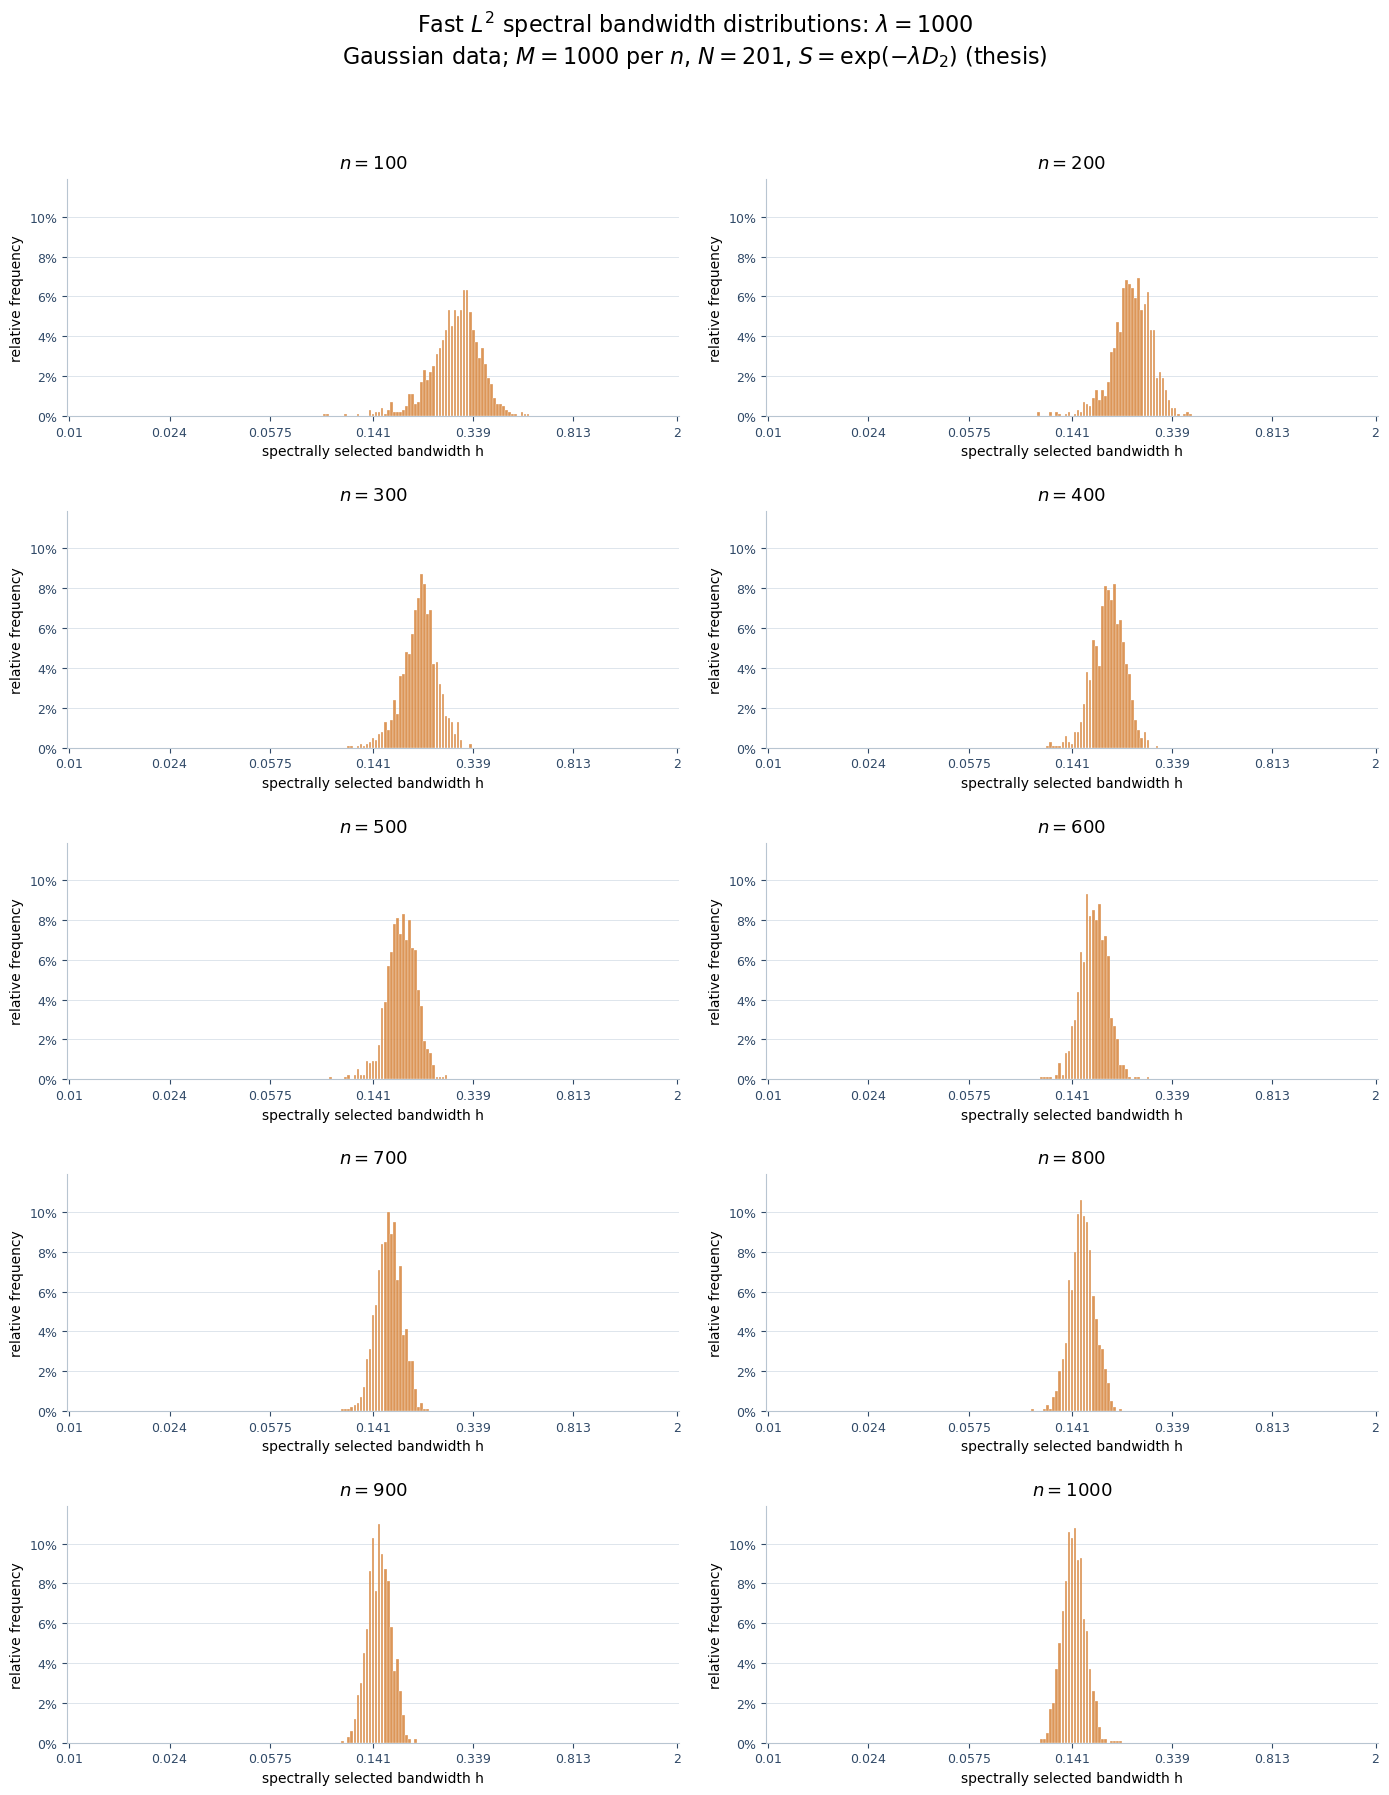

PNG (lambda=1000): /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/d7062cba5620/spectral_l2_lambda1000_M1000_N201.png
PDF directory: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda


In [14]:
if set(additional_results_by_n) != set(SAMPLE_SIZES):
    raise RuntimeError("Finish all ten sample sizes before plotting.")
additional_grid_positions = np.arange(len(h_grid))
additional_ticks = np.unique(np.linspace(0, len(h_grid) - 1, 7, dtype=int))
additional_y_max = 1.08 * max(np.max(additional_result["frequencies"]) for additional_result in additional_results_by_n.values())

for additional_column, additional_lambda_value in enumerate(ADDITIONAL_LAMBDA_VALUES):
    additional_fig, additional_axes = plt.subplots(5, 2, figsize=(14, 18), sharex=True, sharey=True)
    for additional_ax, additional_n in zip(additional_axes.flat, SAMPLE_SIZES):
        additional_ax.bar(
            additional_grid_positions, additional_results_by_n[additional_n]["frequencies"][additional_column],
            width=0.86, color="#D6843B", alpha=0.85, edgecolor="white", linewidth=0.25,
        )
        additional_ax.set_title(rf"$n={additional_n}$", fontsize=13, pad=8)
        additional_ax.set_xticks(additional_ticks, [f"{h_grid[index]:.3g}" for index in additional_ticks])
        additional_ax.set_xlim(-0.7, len(h_grid) - 0.3)
        additional_ax.set_ylim(0, additional_y_max)
        additional_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
        additional_ax.set_xlabel("spectrally selected bandwidth h", fontsize=10)
        additional_ax.set_ylabel("relative frequency", fontsize=10)
        additional_ax.tick_params(labelsize=9, colors="#304967", labelbottom=True, labelleft=True)
        additional_ax.grid(axis="y", color="#DDE5EC", linewidth=0.7)
        additional_ax.set_axisbelow(True)
        for side in ("top", "right"):
            additional_ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            additional_ax.spines[side].set_color("#B8C5D1")
    additional_fig.suptitle(
        rf"Fast $L^2$ spectral bandwidth distributions: $\lambda={additional_lambda_value:g}$" + "\n"
        + rf"Gaussian data; $M={additional_settings['repetitions']}$ per $n$, $N={len(h_grid)}$, "
        + r"$S=\exp(-\lambda D_2)$" + f" ({RUN_PROFILE})",
        fontsize=16, y=0.995,
    )
    additional_fig.tight_layout(rect=(0, 0, 1, 0.965), h_pad=2.0, w_pad=2.0)
    additional_lambda_tag = f"{additional_lambda_value:g}".replace(".", "p").replace("+", "")
    additional_png_path = additional_image_directory / (
        f"spectral_l2_lambda{additional_lambda_tag}_M{additional_settings['repetitions']}_N{len(h_grid)}.png"
    )
    additional_fig.savefig(additional_png_path, dpi=160, bbox_inches="tight")
    plt.show()  # The shared automatic exporter saves each ten-panel figure as a PDF.
    plt.close(additional_fig)
    print(f"PNG (lambda={additional_lambda_value:g}): {additional_png_path}")
print(f"PDF directory: {pdf_output_directory}")


## Comparison: four lambda values superimposed at each sample size

This figure has **ten panels**, one for each $n=100,200,\ldots,1000$. Each panel overlays the four spectral bandwidth distributions for $\lambda=1,10,100,1000$, with a common colour legend and shared axis limits. Step outlines and light fills keep overlapping distributions visible. The vertical axis shows relative frequency on the same geometric bandwidth grid as the separate figures above.

**Run the setup cell, then the two cells below.** They read the four completed thesis runs saved on disk ($M=1000$ each), including the separate runs for lambda 10 and 100; no simulation cells need to be rerun. The source folders are listed explicitly in `OVERLAY_RUN_IDS`, so this comparison is independent of the current `ADDITIONAL_LAMBDA_VALUES` setting. The runs must have matching settings, bandwidth grids and sample sizes.

The figure is displayed below and saved as a PNG; the setup cell's shared exporter automatically saves a PDF under `outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda/`.

Sources: saved `settings.json` and `frequencies.csv` files in the [lambda 1 run](outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/028fa8664f9c/), [lambda 10 run](outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/1de0f2734d87/), [lambda 100 run](outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/4e41e6f126cf/), and [lambda 1000 run](outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/d7062cba5620/); [automatic PDF exporter](kde_tools/pdf_export.py).


In [ ]:
# Load the completed runs, without calculating KDEs or eigenvectors again.
OVERLAY_PROFILE = "thesis"
OVERLAY_RUN_IDS = {
    1.0: "028fa8664f9c",
    10.0: "1de0f2734d87",
    100.0: "4e41e6f126cf",
    1000.0: "d7062cba5620",
}
overlay_sample_sizes = list(range(100, 1001, 100))
overlay_frequencies = {}
overlay_common_configuration = None

for overlay_lambda, overlay_run_id in OVERLAY_RUN_IDS.items():
    overlay_source_directory = data_output_directory / OVERLAY_PROFILE / overlay_run_id
    overlay_manifest = json.loads((overlay_source_directory / "settings.json").read_text())
    if (overlay_manifest["profile"] != OVERLAY_PROFILE
            or overlay_manifest["lambda_values"] != [overlay_lambda]
            or overlay_manifest["sample_sizes"] != overlay_sample_sizes):
        raise ValueError(f"Unexpected experiment configuration: {overlay_source_directory}")
    overlay_configuration = {
        key: value for key, value in overlay_manifest.items() if key != "lambda_values"
    }
    if overlay_common_configuration is None:
        overlay_common_configuration = overlay_configuration
        overlay_settings = dict(overlay_manifest["settings"])
        overlay_h_grid = bandwidth_grid_linear_in_psi_beta(
            h_min=overlay_settings["h_min"], h_max=overlay_settings["h_max"],
            beta=2.0, grid_size=overlay_settings["grid_size"],
        )
        overlay_repetitions = int(overlay_settings["repetitions"])
    elif overlay_configuration != overlay_common_configuration:
        raise ValueError("The four overlay runs must share all settings except lambda.")

    with (overlay_source_directory / "frequencies.csv").open(newline="") as overlay_stream:
        overlay_rows = list(csv.DictReader(overlay_stream))
    if len(overlay_rows) != len(overlay_sample_sizes) * len(overlay_h_grid):
        raise ValueError(f"Incomplete frequency table: {overlay_source_directory}")
    if any(float(row["lambda"]) != overlay_lambda for row in overlay_rows):
        raise ValueError(f"Unexpected lambda in frequency table: {overlay_source_directory}")
    overlay_frequencies[overlay_lambda] = {}
    for overlay_n in overlay_sample_sizes:
        overlay_point_rows = sorted(
            (row for row in overlay_rows if int(row["n"]) == overlay_n),
            key=lambda row: int(row["grid_index"]),
        )
        if [int(row["grid_index"]) for row in overlay_point_rows] != list(range(len(overlay_h_grid))):
            raise ValueError(f"Missing or duplicate grid positions at n={overlay_n}.")
        if not np.allclose(
            [float(row["h"]) for row in overlay_point_rows], overlay_h_grid,
            rtol=0, atol=1e-15,
        ):
            raise ValueError("The saved bandwidth grid differs from the overlay grid.")
        overlay_counts = np.array([int(row["count"]) for row in overlay_point_rows])
        if np.any(overlay_counts < 0) or overlay_counts.sum() != overlay_repetitions:
            raise ValueError(f"Incomplete distribution: lambda={overlay_lambda:g}, n={overlay_n}.")
        overlay_frequency = overlay_counts / overlay_repetitions
        if not np.allclose(
            overlay_frequency, [float(row["relative_frequency"]) for row in overlay_point_rows],
            rtol=0, atol=1e-15,
        ):
            raise ValueError("Saved frequencies do not agree with the repetition counts.")
        overlay_frequencies[overlay_lambda][overlay_n] = overlay_frequency
    print(f"Loaded lambda={overlay_lambda:g}: {overlay_source_directory}")

print(f"Ready: ten panels, four lambdas per panel, M={overlay_repetitions}, N={len(overlay_h_grid)}.")


Loaded lambda=1: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/028fa8664f9c
Loaded lambda=10: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/1de0f2734d87
Loaded lambda=100: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/4e41e6f126cf
Loaded lambda=1000: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/data/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/d7062cba5620
Ready: ten panels, four lambdas per panel, M=1000, N=201.


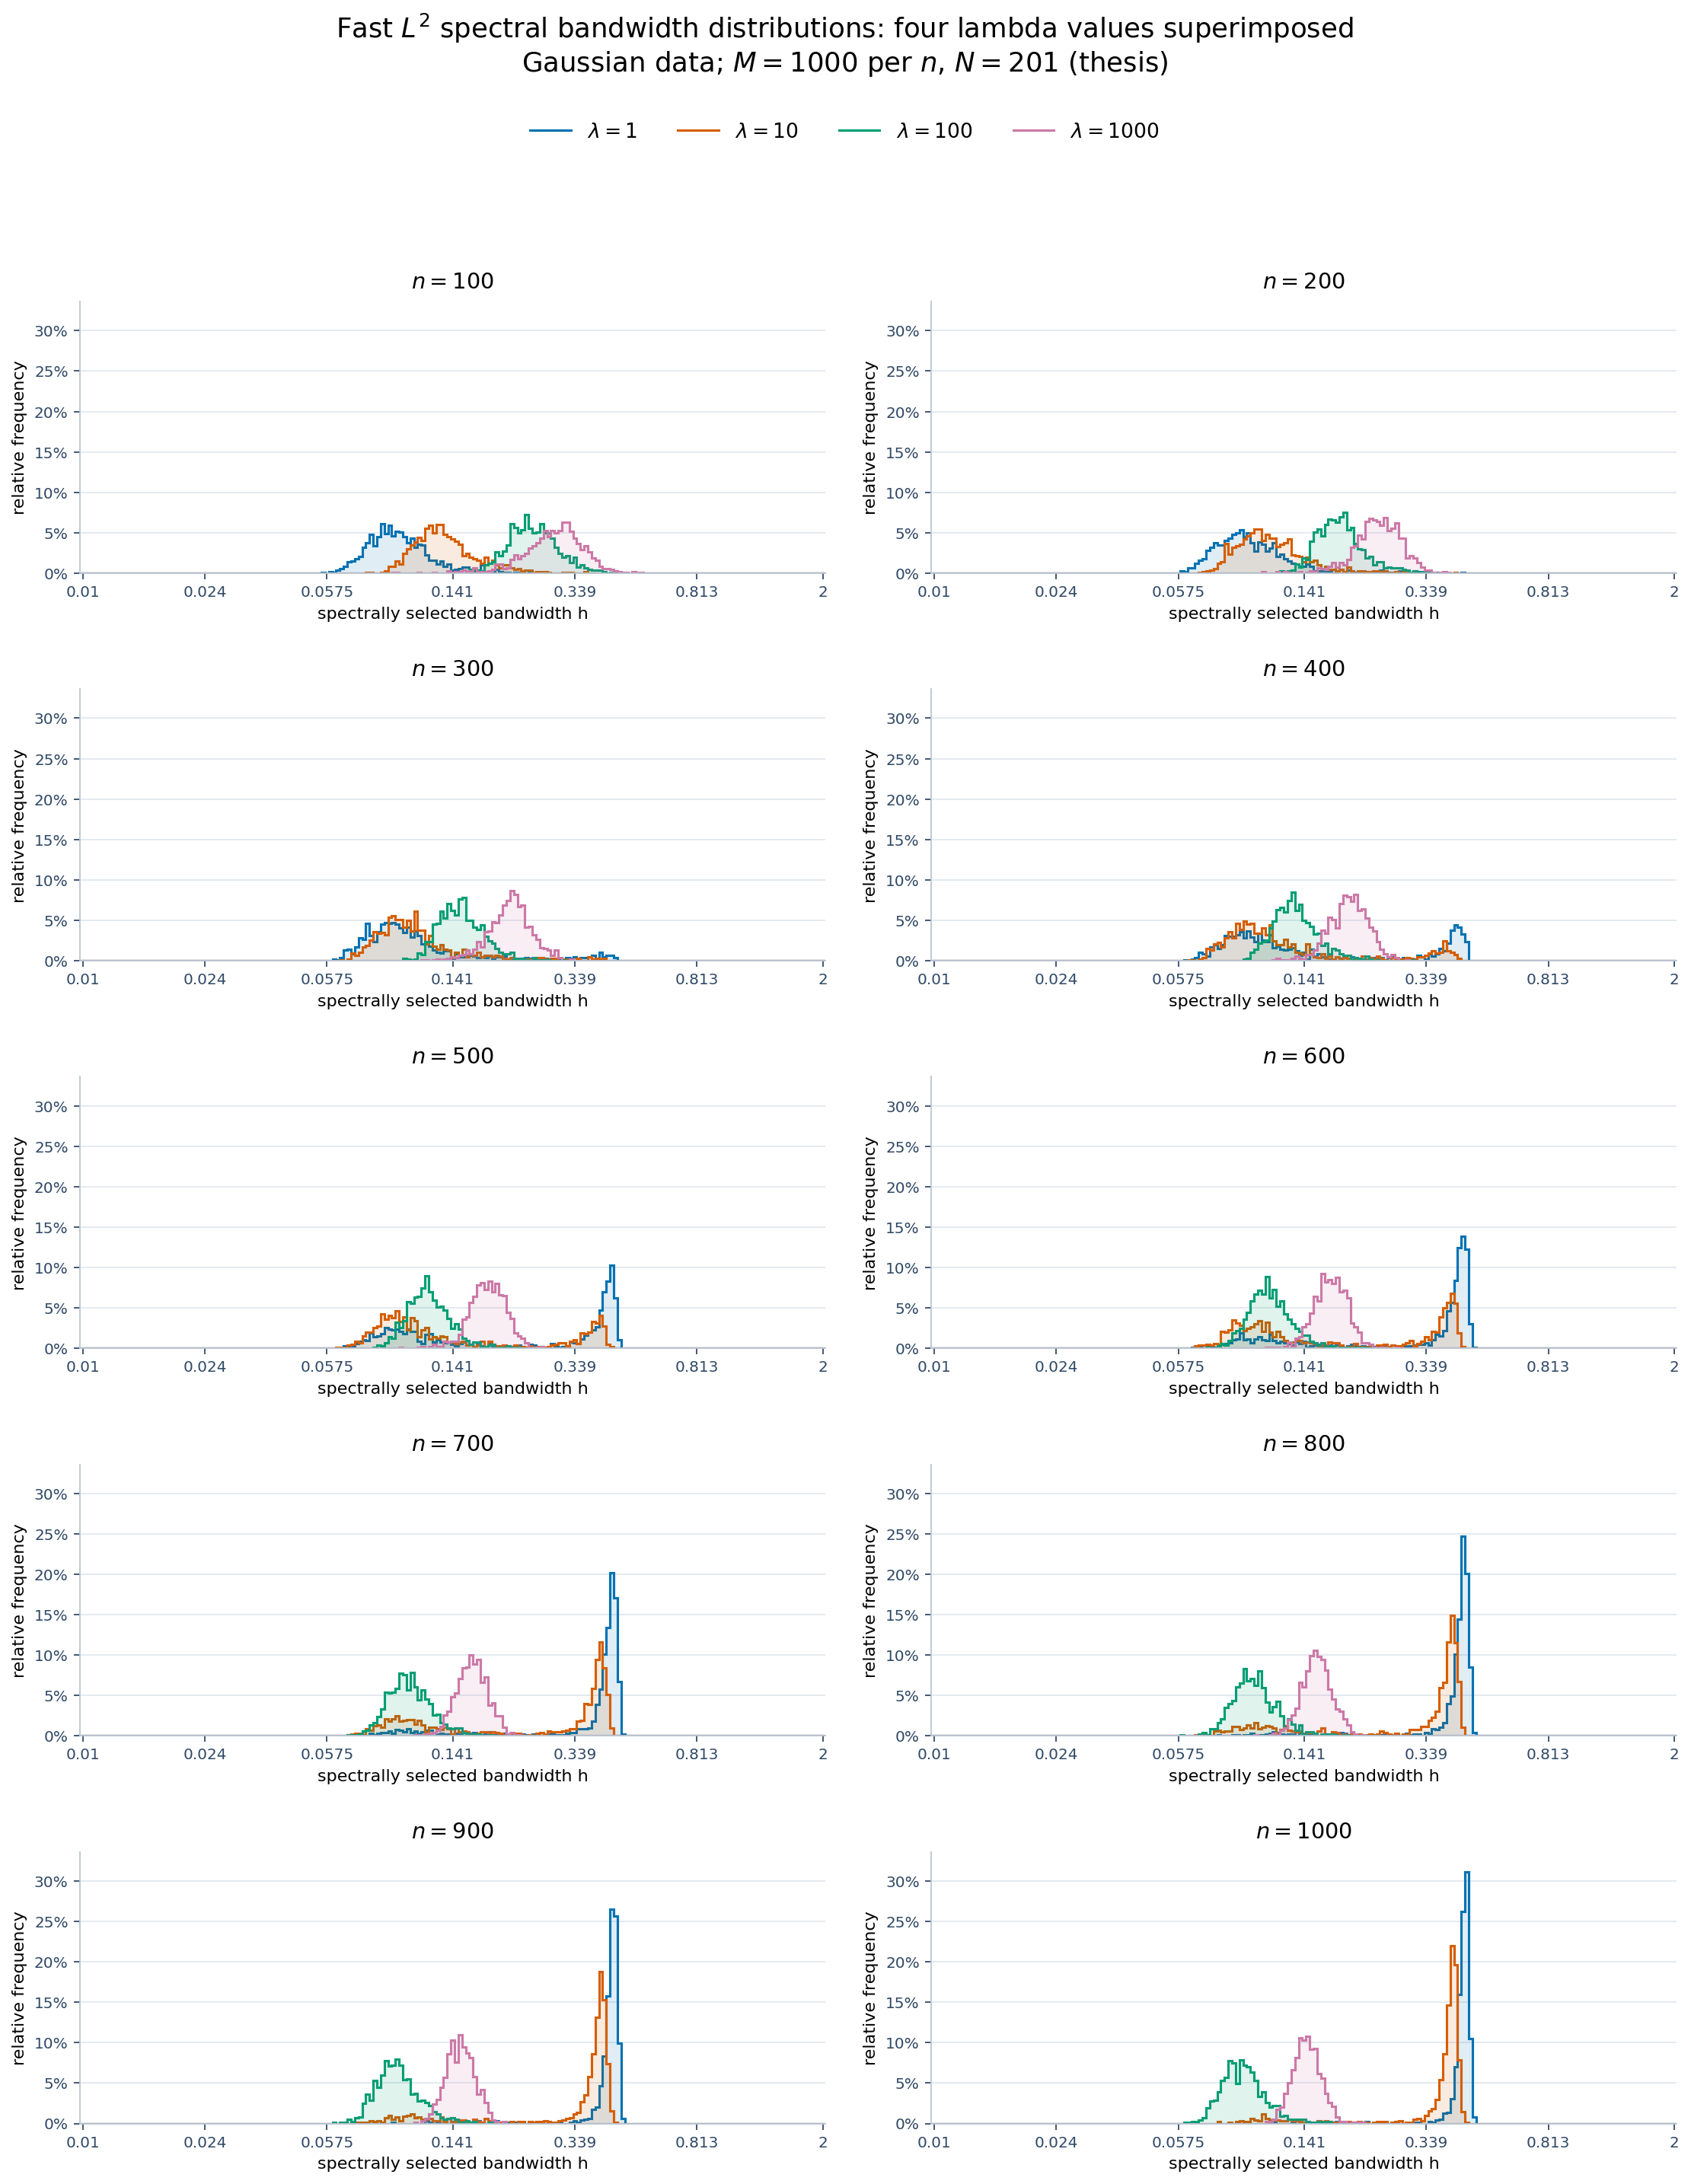

Saved PDF: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda/001_fast_l_2_spectral_bandwidth_distributions_four_lambda_values_superimposed_gaussi.pdf
PNG: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/images/fast_l2_bandwidth_distributions_vs_n_lambda/thesis/overlaid_lambdas/spectral_l2_overlay_lambda1_10_100_1000_M1000_N201.png
PDF directory: /Users/iljasukhanov/MASTERARBEIT/Code/Code_kde/outputs/pdfs/fast_l2_bandwidth_distributions_vs_n_lambda


In [ ]:
overlay_colors = {
    1.0: "#0072B2", 10.0: "#D55E00", 100.0: "#009E73", 1000.0: "#CC79A7",
}
overlay_edges = np.arange(len(overlay_h_grid) + 1) - 0.5
overlay_ticks = np.unique(np.linspace(0, len(overlay_h_grid) - 1, 7, dtype=int))
overlay_y_max = 1.08 * max(
    frequencies.max()
    for distributions in overlay_frequencies.values()
    for frequencies in distributions.values()
)
overlay_fig, overlay_axes = plt.subplots(5, 2, figsize=(14, 18), sharex=True, sharey=True)

for overlay_ax, overlay_n in zip(overlay_axes.flat, overlay_sample_sizes):
    for overlay_lambda, overlay_color in overlay_colors.items():
        overlay_values = overlay_frequencies[overlay_lambda][overlay_n]
        overlay_ax.stairs(
            overlay_values, overlay_edges, fill=True, color=overlay_color,
            alpha=0.12, linewidth=0,
        )
        overlay_ax.stairs(
            overlay_values, overlay_edges, color=overlay_color, linewidth=1.4,
            label=rf"$\lambda={overlay_lambda:g}$",
        )
    overlay_ax.set_title(rf"$n={overlay_n}$", fontsize=13, pad=8)
    overlay_ax.set_xticks(overlay_ticks, [f"{overlay_h_grid[index]:.3g}" for index in overlay_ticks])
    overlay_ax.set_xlim(-0.7, len(overlay_h_grid) - 0.3)
    overlay_ax.set_ylim(0, overlay_y_max)
    overlay_ax.yaxis.set_major_formatter(PercentFormatter(xmax=1.0, decimals=0))
    overlay_ax.set_xlabel("spectrally selected bandwidth h", fontsize=10)
    overlay_ax.set_ylabel("relative frequency", fontsize=10)
    overlay_ax.tick_params(labelsize=9, colors="#304967", labelbottom=True, labelleft=True)
    overlay_ax.grid(axis="y", color="#DDE5EC", linewidth=0.7)
    overlay_ax.set_axisbelow(True)
    for overlay_side in ("top", "right"):
        overlay_ax.spines[overlay_side].set_visible(False)
    for overlay_side in ("left", "bottom"):
        overlay_ax.spines[overlay_side].set_color("#B8C5D1")

overlay_fig.suptitle(
    r"Fast $L^2$ spectral bandwidth distributions: four lambda values superimposed" + "\n"
    + rf"Gaussian data; $M={overlay_repetitions}$ per $n$, $N={len(overlay_h_grid)}$"
    + f" ({OVERLAY_PROFILE})",
    fontsize=16, y=0.995,
)
overlay_handles, overlay_labels = overlay_axes.flat[0].get_legend_handles_labels()
overlay_fig.legend(
    overlay_handles, overlay_labels, loc="upper center", bbox_to_anchor=(0.5, 0.953),
    ncol=4, frameon=False, fontsize=12,
)
overlay_fig.tight_layout(rect=(0, 0, 1, 0.925), h_pad=2.0, w_pad=2.0)
overlay_image_directory = image_output_directory / OVERLAY_PROFILE / "overlaid_lambdas"
overlay_image_directory.mkdir(parents=True, exist_ok=True)
overlay_png_path = overlay_image_directory / (
    f"spectral_l2_overlay_lambda1_10_100_1000_M{overlay_repetitions}_N{len(overlay_h_grid)}.png"
)
overlay_fig.savefig(overlay_png_path, dpi=160, bbox_inches="tight")
plt.show()  # The setup cell's shared exporter saves the overlaid figure as a PDF.
plt.close(overlay_fig)
print(f"PNG: {overlay_png_path}")
print(f"PDF directory: {pdf_output_directory}")
